# Phase 1: Load, clean, join, and split freMTPL2

French Motor Third-Party Liability dataset: `freMTPL2freq` (one row per policy) and `freMTPL2sev` (one row per claim).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

freq = fetch_openml(data_id=41214, as_frame=True).frame   # one row per policy
sev  = fetch_openml(data_id=41215, as_frame=True).frame   # one row per claim

## Task 1: Inspect both tables

In [2]:
print("freq:", freq.shape)
print("sev:", sev.shape)
freq.info()
sev.info()

freq: (678013, 12)
sev: (26639, 2)
<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678013 non-null  float64 
 1   ClaimNb     678013 non-null  int64   
 2   Exposure    678013 non-null  float64 
 3   Area        678013 non-null  category
 4   VehPower    678013 non-null  int64   
 5   VehAge      678013 non-null  int64   
 6   DrivAge     678013 non-null  int64   
 7   BonusMalus  678013 non-null  int64   
 8   VehBrand    678013 non-null  category
 9   VehGas      678013 non-null  str     
 10  Density     678013 non-null  int64   
 11  Region      678013 non-null  category
dtypes: category(3), float64(2), int64(6), str(1)
memory usage: 54.0 MB
<class 'pandas.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol

In [3]:
freq.describe()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405
std,1.641783e+06,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,6.114330e+06,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000


In [4]:
sev.describe()

,IDpol,ClaimAmount
count,2.663900e+04,2.663900e+04
mean,2.279864e+06,2.278536e+03
std,1.577202e+06,2.929748e+04
min,1.390000e+02,1.000000e+00
25%,1.087642e+06,6.868100e+02
50%,2.137413e+06,1.172000e+03
75%,3.180162e+06,1.228080e+03
max,6.113971e+06,4.075401e+06


In [5]:
print(freq.isna().sum())
print(sev.isna().sum())
for col in ["Area", "VehBrand", "VehGas", "Region"]:
    print(col, freq[col].unique()[:5])

IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0
dtype: int64
IDpol          0
ClaimAmount    0
dtype: int64
Area ['D', 'B', 'E', 'C', 'F']
Categories (6, str): ['A', 'B', 'C', 'D', 'E', 'F']
VehBrand ['B12', 'B6', 'B3', 'B2', 'B5']
Categories (11, str): ['B1', 'B10', 'B11', 'B12', ..., 'B3', 'B4', 'B5', 'B6']
VehGas <ArrowStringArray>
[''Regular'', ''Diesel'']
Length: 2, dtype: str
Region ['R82', 'R22', 'R72', 'R31', 'R91']
Categories (22, str): ['R11', 'R21', 'R22', 'R23', ..., 'R83', 'R91', 'R93', 'R94']


In [6]:
# Fixes found during inspection
freq["IDpol"] = freq["IDpol"].astype(int)
freq["VehGas"] = freq["VehGas"].str.strip("'")

## Task 1: Data inspection findings

**Size**
- `freq`: 678,013 policies, 12 columns (one row per policy)
- `sev`: 26,639 claims, 2 columns (one row per claim)
- No missing values in either table

**Data issues fixed**
- `IDpol` was float in `freq` but int in `sev`, so converted `freq` to int for a clean join
- `VehGas` values had stray quote marks (`'Regular'`), so stripped them

**Things to investigate**
- **Missing claim amounts:** `ClaimNb` totals about 36,100 claims, but `sev` has only 26,639 rows
- **Exposure above 1:** max is 2.01, but Exposure should be at most 1 year
- **Suspicious extremes:** `ClaimNb` up to 16, `VehAge` and `DrivAge` max at exactly 100, `BonusMalus` up to 230

**Claim costs are extremely skewed**
- Median claim about €1,172, mean about €2,279, max about €4.08 million
- Many claims share identical amounts (e.g. €1,204.00)

## Task 2: Aggregate severity to one row per policy

In [7]:
sev_agg = (
    sev.groupby("IDpol")
       .agg(ClaimAmount=("ClaimAmount", "sum"),
            ClaimNbSev=("ClaimAmount", "count"))
       .reset_index()
)

print("Policies with claims in sev:", sev_agg.shape[0])
print("Unique IDpol in sev:", sev["IDpol"].nunique())
print("Total amount before:", sev["ClaimAmount"].sum())
print("Total amount after:", sev_agg["ClaimAmount"].sum())
print("Max claims on one policy:", sev_agg["ClaimNbSev"].max())

Policies with claims in sev: 24950
Unique IDpol in sev: 24950
Total amount before: 60697930.68000001
Total amount after: 60697930.68
Max claims on one policy: 66


## Task 3: Join

In [8]:
df = freq.merge(sev_agg, on="IDpol", how="left")
df["ClaimAmount"] = df["ClaimAmount"].fillna(0)
df["ClaimNbSev"] = df["ClaimNbSev"].fillna(0).astype(int)

print("Rows before:", freq.shape[0])
print("Rows after:", df.shape[0])
print("Total amount in df:", df["ClaimAmount"].sum())

Rows before: 678013
Rows after: 678013
Total amount in df: 59909216.5


## Task 4: Data quality checks

In [9]:
no_amount = df[(df["ClaimNb"] > 0) & (df["ClaimAmount"] == 0)]
print("Policies with claims but no amount:", len(no_amount))
print("Claims affected:", no_amount["ClaimNb"].sum())

orphans = sev_agg[~sev_agg["IDpol"].isin(freq["IDpol"])]
print("Orphan policies in sev:", len(orphans))
print("Orphan claim amount:", orphans["ClaimAmount"].sum())

has_both = df[(df["ClaimNb"] > 0) & (df["ClaimNbSev"] > 0)]
mismatch = has_both[has_both["ClaimNb"] != has_both["ClaimNbSev"]]
print("Policies with count mismatch:", len(mismatch))

Policies with claims but no amount: 9116
Claims affected: 9657
Orphan policies in sev: 6
Orphan claim amount: 788714.1799999999
Policies with count mismatch: 1


In [10]:
# Decision: count only claims with a recorded cost
df["ClaimNb"] = df["ClaimNbSev"]

print((df["ClaimNb"] > 0).sum(), "policies with claims")
print(((df["ClaimNb"] > 0) & (df["ClaimAmount"] == 0)).sum(), "with claims but no amount")

24944 policies with claims
0 with claims but no amount


## Task 4: Data quality checks and decisions

- **Claims with no cost:** 9,116 policies (9,657 claims, about 27% of all claims) had a claim count but no recorded amount. **Decision:** count only claims with a recorded cost, so frequency and severity both describe claims the insurer actually paid.
- **Orphan claims:** 6 policies in `sev` (about €789k, roughly 1.3% of total cost) had no matching policy in `freq`. **Decision:** dropped, since they can't be priced without policy features.
- **Count mismatch:** 1 policy had 2 claims in `freq` but 1 in `sev`; resolved by the decision above.

## Task 5: Distributions

Policies with Exposure > 1: 1224


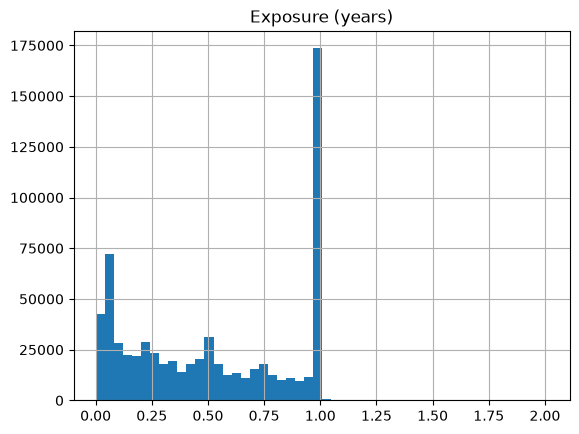

In [11]:
print("Policies with Exposure > 1:", (df["Exposure"] > 1).sum())
df["Exposure"].hist(bins=50)
plt.title("Exposure (years)")
plt.show()

In [12]:
print(df["ClaimNb"].value_counts().sort_index())

ClaimNb
0     653069
1      23571
2       1298
3         62
4          5
5          2
6          1
8          1
9          1
11         2
16         1
Name: count, dtype: int64


count    2.494400e+04
mean     2.401749e+03
std      3.026475e+04
min      1.000000e+00
25%      7.497875e+02
50%      1.172000e+03
75%      1.346400e+03
max      4.075401e+06
Name: ClaimAmount, dtype: float64
Claims over €50k: 88
Claims over €100k: 42


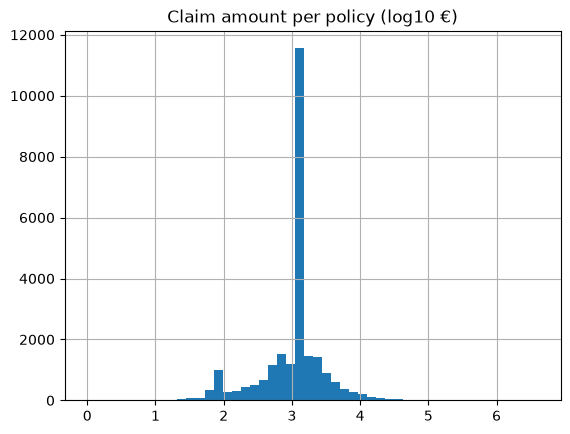

ClaimAmount
1204.00    4319
1128.12    2766
1172.00    1882
1128.00     753
602.00      373
1320.00     149
2408.00     132
586.00       89
564.06       87
3204.00      85
Name: count, dtype: int64


In [13]:
claims = df[df["ClaimAmount"] > 0]
print(claims["ClaimAmount"].describe())
print("Claims over €50k:", (claims["ClaimAmount"] > 50_000).sum())
print("Claims over €100k:", (claims["ClaimAmount"] > 100_000).sum())

np.log10(claims["ClaimAmount"]).hist(bins=50)
plt.title("Claim amount per policy (log10 €)")
plt.show()

print(claims["ClaimAmount"].value_counts().head(10))

In [14]:
total = claims["ClaimAmount"].sum()
for cutoff in [50_000, 100_000, 500_000]:
    big = claims.loc[claims["ClaimAmount"] > cutoff, "ClaimAmount"].sum()
    print(f"Claims over €{cutoff:,}: {big / total:.1%} of total cost")

print("Claims per year:", df["ClaimNb"].sum() / df["Exposure"].sum())

Claims over €50,000: 30.0% of total cost
Claims over €100,000: 24.8% of total cost
Claims over €500,000: 12.6% of total cost
Claims per year: 0.0737630150748181


## Task 5: Distributions

- **Exposure:** most policies active well under a year; spikes at about 1 month, 6 months, and a full year (about 175k). Very few above 1, so cap at 1.
- **Claim counts:** 96.3% of policies had no paid claim; 3.7% had at least one. Only 12 policies had 4+ claims (max 16), so cap `ClaimNb` at 4.
- **Claim costs:** about 39% of claims are exactly one of four fixed amounts (€1,204, €1,128.12, €1,172, €1,128), with halves and doubles also common (€602, €2,408). These look like flat-rate settlements, so severity mixes standardized payouts with truly variable costs.
- **Large claims:** 88 claims over €50k and 42 over €100k make up 30.0% and 24.8% of total cost. Capping threshold to be chosen on training data only.
- **Updated frequency:** about 0.074 paid claims per year of exposure.

## Task 6: Cap, split, and save

In [15]:
# Fixed-rule caps (safe before the split)
df["Exposure"] = df["Exposure"].clip(upper=1)
df["ClaimNb"] = df["ClaimNb"].clip(upper=4)

train, test = train_test_split(df, test_size=0.2, random_state=42)

print("Train:", train.shape)
print("Test:", test.shape)
print("Train claim rate:", train["ClaimNb"].sum() / train["Exposure"].sum())
print("Test claim rate:", test["ClaimNb"].sum() / test["Exposure"].sum())

Train: (542410, 14)
Test: (135603, 14)
Train claim rate: 0.07325538219707056
Test claim rate: 0.07539507012571074


In [16]:
os.makedirs("../data", exist_ok=True)
train.to_parquet("../data/train.parquet", index=False)
test.to_parquet("../data/test.parquet", index=False)
print(os.listdir("../data"))

['test.parquet', 'train.parquet']


## Task 6: Split

- Capped Exposure at 1 and ClaimNb at 4 (fixed rules, applied before splitting)
- 80/20 random split, `random_state=42`
- Saved to `data/train.parquet` and `data/test.parquet`
- **The test set is not opened again until Phase 4.**